# Лекция: Компьютерное зрение
## Self-Supervised Learning & Metric Learning

**Преподаватель:** Весельев Александр, Т-Банк

**Аудитория:** МФТИ

---

## Содержание

1. Обучающие сигналы для визуальных представлений
   - Contrastive: SimCLR
   - Self-distillation: BYOL, DINOv1
   - Masked/predictive: MAE, BEiT, iBOT, I-JEPA
   - Foundation features: DINOv2/v3
2. Vision-language embeddings
   - CLIP, SigLIP, SigLIP2
3. Протоколы оценки
   - frozen k-NN, linear probe, transfer
   - метрики retrieval, verification и identification
4. Supervised metric learning
   - sampling/mining, Triplet, SupCon, proxies
   - ArcFace, AdaFace и масштабирование на большое число классов
5. Векторный поиск
   - exact baseline, HNSW, IVF-PQ

## 1. Self-Supervised Learning

### 1.1 SimCLR

[arxiv](https://arxiv.org/abs/2002.05709)

<img src="./assets/simclr.png" alt="Архитектура SimCLR" width="600">

**Идея**

Self-Supervised метод обучения:
- Две аугментированные views одного изображения образуют известную positive pair
- Остальные views в batch — negatives
- Temperature управляет концентрацией softmax, сочетание аугментаций задаёт желаемые инвариантности, projection head отделяет contrastive space от представления для downstream-задач.
- В реальной реализации используем vectorized cross-entropy/log-sum-exp, а не наивные `exp`, чтобы избежать численной нестабильности.


**Псевдокод**

```python
# входные данные:
#   N   - batch size
#   tau - temperature constant
#   f   - encoder network
#   g   - projection head
#   T   - семейство аугментаций

for batch in dataloader:  # batch = {x_k}_{k=1}^N
    x = batch  # x[0], ..., x[N-1]

    h = [None] * (2 * N)
    z = [None] * (2 * N)

    for k in range(N):
        t1 = sample_augmentation(T)
        t2 = sample_augmentation(T)

        # первая аугментация
        x_2k_1 = t1(x[k])
        h[2 * k] = f(x_2k_1)  # representation
        z[2 * k] = g(h[2 * k])  # projection

        # вторая аугментация
        x_2k = t2(x[k])
        h[2 * k + 1] = f(x_2k)  # representation
        z[2 * k + 1] = g(h[2 * k + 1])  # projection

    s = [[0.0 for _ in range(2 * N)] for _ in range(2 * N)]

    for i in range(2 * N):
        for j in range(2 * N):
            s[i][j] = cosine_similarity(z[i], z[j])

    def l(i, j):
        numerator = exp(s[i][j] / tau)

        denominator = 0.0
        for k in range(2 * N):
            if k != i:
                denominator += exp(s[i][k] / tau)

        return -log(numerator / denominator)

    L = 0.0
    for k in range(N):
        L += l(2 * k, 2 * k + 1) + l(2 * k + 1, 2 * k)

    L = L / (2 * N)

    update(f, g, loss=L)
return f
```

## 1.2 BYOL

[paper](https://arxiv.org/abs/2006.07733)

<img src="./assets/byol.png" alt="Архитектура BYOL" width="600">

Online-ветвь (encoder + projector + predictor) учится предсказывать target representation другой view с применением stop-gradient. Параметры target-ветви инициализируются из online-ветви и обновляются на месте через EMA:

$$\theta_t \leftarrow \tau\theta_t + (1-\tau)\theta_o.$$

BYOL не использует явные negatives. Асимметрия predictor, stop-gradient и медленно обновляемая target-ветвь вместе предотвращают тривиальный collapse. Для inference сохраняется только encoder.


## 1.3 BEiT: discrete masked tokens

[paper](https://arxiv.org/abs/2106.08254)

<img src="./assets/beit.png" alt="Архитектура BEiT" width="600">

Выбранные позиции patches заменяются обучаемым mask embedding. ViT предсказывает дискретные visual tokens, полученные от отдельно предобученного dVAE tokenizer. BEiT исторически важен, но внешний tokenizer делает его менее удобным, чем MAE или предсказание признаков teacher.


## 1.4 iBOT: online teacher targets

[paper](https://arxiv.org/abs/2111.07832)

<img src="./assets/ibot.png" alt="Архитектура iBOT" width="800">

iBOT отказывается от внешнего tokenizer: EMA teacher формирует global CLS и patch targets, а student получает маскированный вход. Patch loss вычисляется только для пространственно соответствующих областей разных crops. Это переход от предсказания токенов в BEiT к схеме обучения DINOv2.


## 1.5 Dino

### DinoV1

[arxiv](https://arxiv.org/abs/2104.14294)

<img src="./assets/dinov1.png" alt="Архитектура DINOv1" width="400">

DINO использует две global crops и несколько local crops. Teacher видит только global views, student — global и local; cross-view loss сопоставляет разные views. Centering не даёт одному измерению доминировать, sharpening уменьшает entropy target distribution, EMA teacher и stop-gradient стабилизируют self-distillation. Псевдокод ниже показывает упрощённый случай двух global views; multi-crop — существенная часть полного метода.

**Псевдокод**

```python
# gs : student network
# gt : teacher network
# C  : вектор центра, размерность [K]
# tps: student temperature
# tpt: teacher temperature
# l  : teacher momentum
# m  : center momentum

gt.params = gs.params.copy()

for x in loader:
    x1 = augment(x)
    x2 = augment(x)

    s1 = gs(x1)  # выходы student, размерность [n, K]
    s2 = gs(x2)

    t1 = gt(x1)  # выходы teacher, размерность [n, K]
    t2 = gt(x2)

    loss = H(t1, s2) / 2 + H(t2, s1) / 2

    optimizer.zero_grad()
    loss.backward()  # градиент проходит только через student
    optimizer.step()  # обновление student

    # обновление teacher через EMA параметров student
    for p_t, p_s in zip(gt.params, gs.params):
        p_t.data = l * p_t.data + (1 - l) * p_s.data

    # обновление центра
    batch_center = concat([t1, t2]).mean(dim=0)
    C = m * C + (1 - m) * batch_center


def H(t, s):
    t = detach(t)  # stop-gradient для teacher
    s = softmax(s / tps, dim=1)  # вероятности student
    t = softmax((t - C) / tpt, dim=1)  # teacher centering + sharpening
    return -(t * log(s)).sum(dim=1).mean()
```

### DinoV2

[arxiv](https://arxiv.org/abs/2304.07193)

*Отличие с v1*

- curated LVD-142M: deduplication, balancing и retrieval-based data curation важны не меньше масштаба
- DINO image-level objective + iBOT masked patch objective
- Sinkhorn-Knopp teacher targets и KoLeo regularization для равномерного embedding space
- схема масштабирования обучения, high-resolution adaptation и distillation небольших student-моделей из крупного teacher
- качество dense patch features оценивается отдельно от качества классификации всего изображения

### DinoV3

[arxiv](https://arxiv.org/abs/2508.10104)

*Отличие с v2*

- technical report 2025 года (версия и checkpoints проверены 22 октября 2026); используемый checkpoint `lvd1689m` обучен на LVD-1689M (около 1.689B изображений)
- при слишком долгом image-level training dense maps деградируют, даже если global metrics растут
- Gram anchoring сохраняет Gram structure / pairwise similarities patch features относительно anchor model и предотвращает эту деградацию
- обновлённая positional encoding и training recipe улучшают стабильность и переносимость между resolutions


In [1]:
import math
import os
from pathlib import Path
from typing import List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import truststore
from PIL import Image

truststore.inject_into_ssl()

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")


**Визуализация DINOv2**

In [2]:
from pathlib import Path
from typing import List, Sequence, Tuple

from sklearn.decomposition import PCA
from transformers import AutoImageProcessor, AutoModel


dinov2_processor = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
dinov2_model = AutoModel.from_pretrained(
    "facebook/dinov2-small",
).to(device)


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

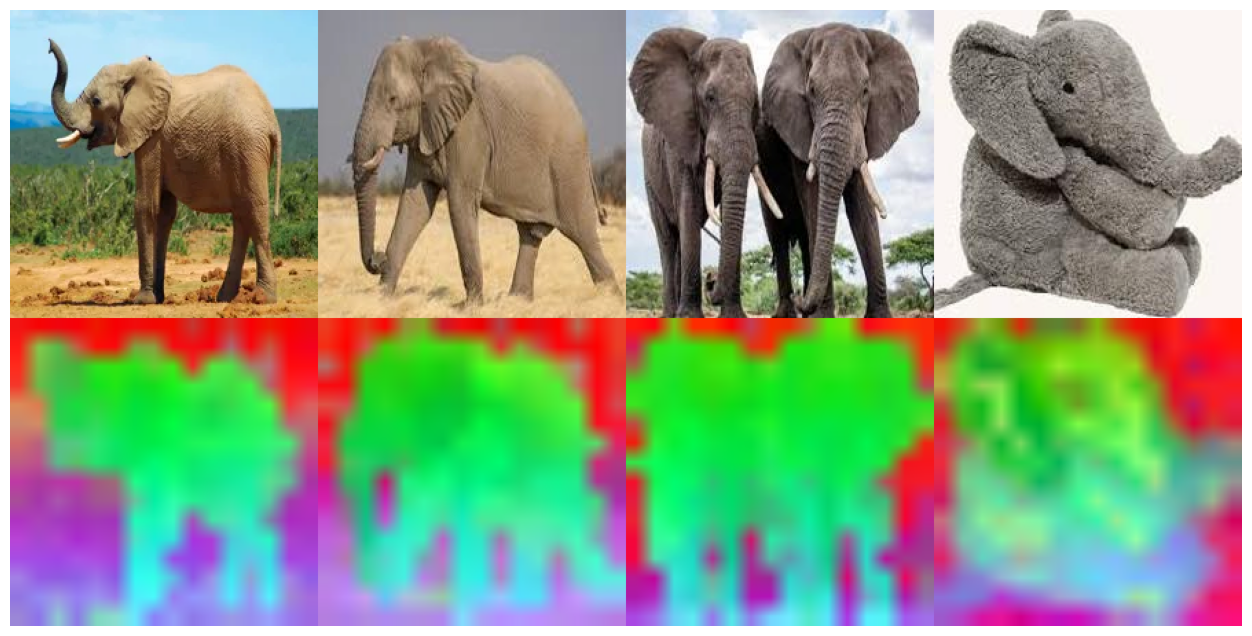

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}


def list_images(directory: Path) -> List[Path]:
    if not directory.exists() or not directory.is_dir():
        raise FileNotFoundError(f"Путь не существует или не является каталогом: {directory}")

    paths = sorted(p for p in directory.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
    if len(paths) < 2:
        raise ValueError(f"В {directory} нужно хотя бы 2 изображения, найдено {len(paths)}.")
    if not (3 <= len(paths) <= 5):
        print(f"[предупреждение] Ожидалось 3–5 изображений, найдено {len(paths)}. Продолжаем.")
    return paths


def load_images(paths: Sequence[Path]) -> List[Image.Image]:
    images: List[Image.Image] = []
    for path in paths:
        with Image.open(path) as img:
            images.append(img.convert("RGB"))
    return images


@torch.no_grad()
def extract_patch_tokens(
    model: AutoModel,
    processor: AutoImageProcessor,
    images: Sequence[Image.Image],
    device: str,
) -> Tuple[List[np.ndarray], List[Tuple[int, int]], List[Image.Image]]:
    patch_tokens_per_image: List[np.ndarray] = []
    patch_grids: List[Tuple[int, int]] = []
    processed_images: List[Image.Image] = []

    for image in images:
        inputs = processor(images=image, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(device)
        display_tensor = inputs["pixel_values"][0].cpu()
        mean = torch.tensor(processor.image_mean).view(3, 1, 1)
        std = torch.tensor(processor.image_std).view(3, 1, 1)
        display_array = ((display_tensor * std + mean).clamp(0, 1) * 255).byte()
        processed_images.append(Image.fromarray(display_array.permute(1, 2, 0).numpy()))

        outputs = model(pixel_values=pixel_values)
        hidden = outputs.last_hidden_state  # [1, 1 + num_patches, dim]
        patch_tokens = hidden[:, 1:, :].squeeze(0).cpu().numpy()  # исключаем CLS token

        patch_size = int(model.config.patch_size)
        h_patches = pixel_values.shape[-2] // patch_size
        w_patches = pixel_values.shape[-1] // patch_size
        if h_patches * w_patches != patch_tokens.shape[0]:
            raise ValueError("Число patch tokens не соответствует геометрии выхода processor")
        patch_tokens_per_image.append(patch_tokens)
        patch_grids.append((h_patches, w_patches))

    return patch_tokens_per_image, patch_grids, processed_images


def fit_joint_pca(patch_tokens_per_image: Sequence[np.ndarray]) -> Tuple[PCA, np.ndarray]:
    joint_tokens = np.concatenate(patch_tokens_per_image, axis=0)
    pca = PCA(n_components=3, svd_solver="full")
    joint_pca = pca.fit_transform(joint_tokens)
    return pca, joint_pca


def robust_minmax(x: np.ndarray, low_q: float = 0.01, high_q: float = 0.99) -> np.ndarray:
    lo = np.quantile(x, low_q, axis=0, keepdims=True)
    hi = np.quantile(x, high_q, axis=0, keepdims=True)
    denom = np.maximum(hi - lo, 1e-8)
    y = (x - lo) / denom
    return np.clip(y, 0.0, 1.0)


def split_joint_projection(joint_projection: np.ndarray, counts: Sequence[int]) -> List[np.ndarray]:
    out: List[np.ndarray] = []
    start = 0
    for count in counts:
        out.append(joint_projection[start:start + count])
        start += count
    return out


def projection_to_rgb_map(proj: np.ndarray, patch_grid: Tuple[int, int]) -> np.ndarray:
    rgb = robust_minmax(proj)
    h_patches, w_patches = patch_grid
    return rgb.reshape(h_patches, w_patches, 3)


def upsample_patch_map(rgb_map: np.ndarray, out_hw: Tuple[int, int]) -> np.ndarray:
    tensor = torch.from_numpy(rgb_map).permute(2, 0, 1).unsqueeze(0).float()
    up = F.interpolate(tensor, size=out_hw, mode="bilinear", align_corners=False)
    up = up.squeeze(0).permute(1, 2, 0).numpy()
    up = np.clip(up * 255.0, 0, 255).astype(np.uint8)
    return up


def make_grid(rows: List[List[Image.Image]]) -> Image.Image:
    n_cols = max(len(row) for row in rows)
    cell_widths = [max(row[c].width for row in rows if c < len(row)) for c in range(n_cols)]
    cell_heights = [max(img.height for img in row) for row in rows]

    total_w = sum(cell_widths)
    total_h = sum(cell_heights)
    canvas = Image.new("RGB", (total_w, total_h), color=(255, 255, 255))

    y = 0
    for r, row in enumerate(rows):
        x = 0
        for c, img in enumerate(row):
            canvas.paste(img, (x, y))
            x += cell_widths[c]
        y += cell_heights[r]
    return canvas


def visualise_dinov2(model: AutoModel, processor: AutoImageProcessor, input_directory: Path) -> None:
    image_paths = list_images(input_directory)
    images = load_images(image_paths)

    model.eval()

    patch_tokens_per_image, patch_grids, processed_images = extract_patch_tokens(
        model=model,
        processor=processor,
        images=images,
        device=device,
    )

    _, joint_projection = fit_joint_pca(patch_tokens_per_image)
    counts = [x.shape[0] for x in patch_tokens_per_image]
    split_projection = split_joint_projection(joint_projection, counts)

    original_row: List[Image.Image] = []
    pca_row: List[Image.Image] = []

    for image, proj, patch_grid in zip(
        processed_images, split_projection, patch_grids
    ):
        rgb_map = projection_to_rgb_map(proj, patch_grid)
        rgb_up = upsample_patch_map(rgb_map, (image.height, image.width))

        original_row.append(image)
        pca_row.append(Image.fromarray(rgb_up))
        
    grid = make_grid([original_row, pca_row])
    
    plt.figure(figsize=(16, 8))
    plt.imshow(np.array(grid))
    plt.axis("off")
    plt.show()


visualise_dinov2(dinov2_model, dinov2_processor, Path("assets/dinov2"))
del dinov2_model, dinov2_processor
if device.type == "cuda":
    torch.cuda.empty_cache()
elif device.type == "mps":
    torch.mps.empty_cache()

**Визуализация DINOv3**

> Checkpoint `facebook/dinov3-vits16-pretrain-lvd1689m` может требовать принятия лицензии и авторизации Hugging Face. До запуска выполните `huggingface_hub.login()` или задайте `HF_TOKEN`; без доступа следующая ячейка завершится ошибкой загрузки.

In [4]:
# from huggingface_hub import login


# login()


def pick_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def pick_dtype(device: torch.device) -> torch.dtype:
    if device.type == "cuda":
        if torch.cuda.is_bf16_supported():
            return torch.bfloat16
        return torch.float16
    return torch.float32


device = pick_device()
dtype = pick_dtype(device=device)
RUN_DINOV3 = os.getenv("RUN_DINOV3", "0") == "1"
dinov3_model = None
RUN_DINOV3 = True
if RUN_DINOV3:
    dinov3_model = AutoModel.from_pretrained(
        "facebook/dinov3-vits16-pretrain-lvd1689m", dtype=dtype
    ).to(device)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

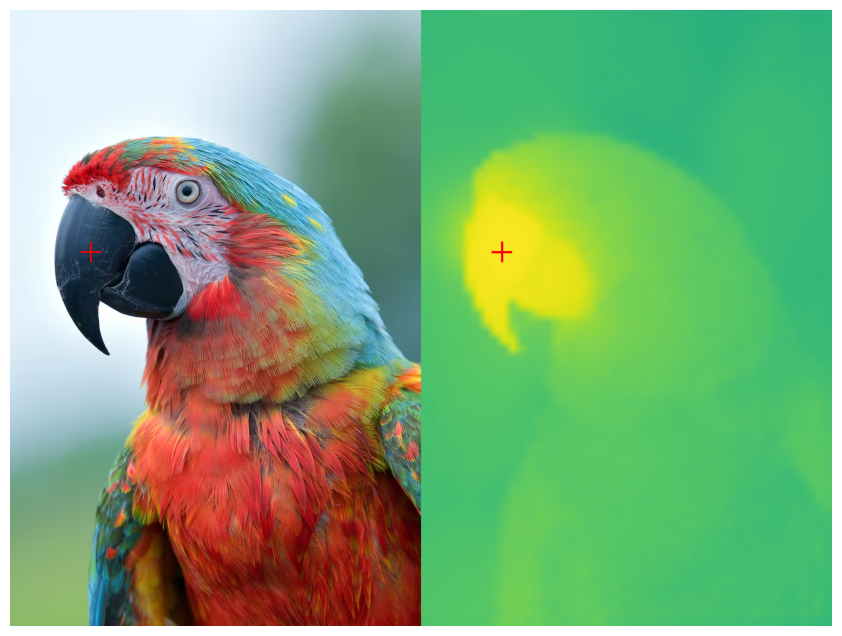

In [5]:
import math
from dataclasses import dataclass
from typing import List, Sequence, Tuple

from PIL import Image, ImageDraw


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


@dataclass(frozen=True)
class ParsedPoint:
    x: int
    y: int


def ensure_rgb(image: Image.Image) -> Image.Image:
    if image.mode != "RGB":
        image = image.convert("RGB")
    return image


def pil_to_normalized_tensor(image: Image.Image) -> torch.Tensor:
    arr = np.asarray(image).astype(np.float32) / 255.0
    if arr.ndim != 3 or arr.shape[2] != 3:
        raise ValueError(f"Ожидалось RGB-изображение, получен массив размерности {arr.shape}")
    tensor = torch.from_numpy(arr).permute(2, 0, 1).contiguous()
    mean = torch.tensor(IMAGENET_MEAN, dtype=tensor.dtype).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD, dtype=tensor.dtype).view(3, 1, 1)
    return (tensor - mean) / std


def pad_image_to_multiple(image: Image.Image, multiple: int) -> Tuple[Image.Image, Tuple[int, int]]:
    w, h = image.size
    new_w = int(math.ceil(w / multiple) * multiple)
    new_h = int(math.ceil(h / multiple) * multiple)
    pad_w = new_w - w
    pad_h = new_h - h
    if pad_w == 0 and pad_h == 0:
        return image, (0, 0)
    canvas = Image.new("RGB", (new_w, new_h), (0, 0, 0))
    canvas.paste(image, (0, 0))
    return canvas, (pad_w, pad_h)


@torch.inference_mode()
def extract_patch_features_single_pass(
    model: AutoModel,
    image: Image.Image,
    device: torch.device,
    dtype: torch.dtype,
) -> torch.Tensor:
    patch_size = int(model.config.patch_size)
    padded_image, _ = pad_image_to_multiple(image, patch_size)
    x = pil_to_normalized_tensor(padded_image).unsqueeze(0).to(device=device, dtype=dtype)

    outputs = model(pixel_values=x)
    hidden = outputs.last_hidden_state
    num_registers = int(getattr(model.config, "num_register_tokens", 0))
    patch_tokens = hidden[:, 1 + num_registers :, :]

    _, _, h, w = x.shape
    grid_h = h // patch_size
    grid_w = w // patch_size
    feat = patch_tokens.reshape(1, grid_h, grid_w, -1)[0]
    return feat.float().cpu()


@torch.inference_mode()
def extract_patch_features_tiled(
    model: AutoModel,
    image: Image.Image,
    device: torch.device,
    dtype: torch.dtype,
    tile_size: int,
    tile_overlap: int,
) -> torch.Tensor:
    patch_size = int(model.config.patch_size)
    tile_size = max(tile_size, patch_size)
    tile_size = (tile_size // patch_size) * patch_size
    if tile_size < patch_size:
        tile_size = patch_size

    tile_overlap = max(0, tile_overlap)
    tile_overlap = (tile_overlap // patch_size) * patch_size
    if tile_overlap >= tile_size:
        raise ValueError("Значение --tile-overlap должно быть меньше --tile-size")

    padded_image, _ = pad_image_to_multiple(image, patch_size)
    padded_w, padded_h = padded_image.size
    content_grid_w = padded_w // patch_size
    content_grid_h = padded_h // patch_size
    if padded_w < tile_size or padded_h < tile_size:
        expanded = Image.new("RGB", (max(padded_w, tile_size), max(padded_h, tile_size)), (0, 0, 0))
        expanded.paste(padded_image, (0, 0))
        padded_image = expanded
        padded_w, padded_h = padded_image.size
    grid_h = padded_h // patch_size
    grid_w = padded_w // patch_size

    feat_sum = None
    weight_sum = None

    stride = tile_size - tile_overlap
    xs = list(range(0, max(1, padded_w - tile_size + 1), stride))
    ys = list(range(0, max(1, padded_h - tile_size + 1), stride))
    if not xs or xs[-1] != padded_w - tile_size:
        xs.append(max(0, padded_w - tile_size))
    if not ys or ys[-1] != padded_h - tile_size:
        ys.append(max(0, padded_h - tile_size))

    num_registers = int(getattr(model.config, "num_register_tokens", 0))

    for top in ys:
        for left in xs:
            tile = padded_image.crop((left, top, left + tile_size, top + tile_size))
            x = pil_to_normalized_tensor(tile).unsqueeze(0).to(device=device, dtype=dtype)
            outputs = model(pixel_values=x)
            hidden = outputs.last_hidden_state
            patch_tokens = hidden[:, 1 + num_registers :, :]
            tile_grid = tile_size // patch_size
            feat = patch_tokens.reshape(1, tile_grid, tile_grid, -1)[0].float().cpu()

            if feat_sum is None:
                channels = feat.shape[-1]
                feat_sum = torch.zeros((grid_h, grid_w, channels), dtype=torch.float32)
                weight_sum = torch.zeros((grid_h, grid_w, 1), dtype=torch.float32)

            gy0 = top // patch_size
            gx0 = left // patch_size
            gy1 = gy0 + tile_grid
            gx1 = gx0 + tile_grid
            feat_sum[gy0:gy1, gx0:gx1] += feat
            weight_sum[gy0:gy1, gx0:gx1] += 1.0

    assert feat_sum is not None and weight_sum is not None
    feat = feat_sum / weight_sum.clamp_min(1e-6)
    return feat[:content_grid_h, :content_grid_w]


def extract_patch_features(
    model: AutoModel,
    image: Image.Image,
    device: torch.device,
    dtype: torch.dtype,
    force_tiled: bool,
    max_direct_side: int,
    tile_size: int,
    tile_overlap: int,
) -> Tuple[torch.Tensor, str]:
    if not force_tiled and max(image.size) <= max_direct_side:
        try:
            return extract_patch_features_single_pass(model, image, device, dtype), "single-pass"
        except RuntimeError as exc:
            oom_like = any(
                key in str(exc).lower() for key in ["out of memory", "cuda error", "not enough memory"]
            )
            if not oom_like:
                raise
            if device.type == "cuda":
                torch.cuda.empty_cache()

    return (
        extract_patch_features_tiled(
            model=model,
            image=image,
            device=device,
            dtype=dtype,
            tile_size=tile_size,
            tile_overlap=tile_overlap,
        ),
        "tiled",
    )


def compute_similarity_map(
    features: torch.Tensor,
    point: ParsedPoint,
    image_size: Tuple[int, int],
    patch_size: int,
) -> np.ndarray:
    width, height = image_size
    grid_h, grid_w, channels = features.shape

    px = min(point.x // patch_size, grid_w - 1)
    py = min(point.y // patch_size, grid_h - 1)

    flat = features.view(-1, channels)
    flat = F.normalize(flat, dim=-1)
    target = flat[py * grid_w + px]
    sim = torch.matmul(flat, target)
    sim = sim.view(grid_h, grid_w)

    sim_np = sim.numpy()
    sim_np = (sim_np + 1.0) / 2.0
    sim_np = np.clip(sim_np, 0.0, 1.0)

    sim_img = Image.fromarray(np.uint8(sim_np * 255.0), mode="L")
    sim_img = sim_img.resize((width, height), resample=Image.BILINEAR)
    return np.asarray(sim_img).astype(np.float32) / 255.0


def draw_cross(draw: ImageDraw.ImageDraw, x: int, y: int, size: int, color: Tuple[int, int, int], width: int = 3) -> None:
    draw.line((x - size, y, x + size, y), fill=color, width=width)
    draw.line((x, y - size, x, y + size), fill=color, width=width)


def get_marked_image(image: Image.Image, points: Sequence[ParsedPoint], cross_size: int) -> Image.Image:
    marked = image.copy()
    draw = ImageDraw.Draw(marked)
    for p in points:
        draw_cross(draw, p.x, p.y, size=cross_size, color=(255, 0, 0), width=max(2, cross_size // 6))
    return marked


def render_similarity_map(
    sim_map: np.ndarray,
    point: ParsedPoint,
    cross_size: int,
) -> Image.Image:
    rgba = plt.get_cmap("viridis")(sim_map, bytes=True)
    rendered = Image.fromarray(rgba[..., :3], mode="RGB")
    draw = ImageDraw.Draw(rendered)
    draw_cross(draw, point.x, point.y, cross_size, (255, 0, 0), width=4)
    return rendered


def get_grid(original_marked: Image.Image, similarity_images: Sequence[Image.Image]) -> Image.Image:
    tiles = [original_marked, *similarity_images]
    cols = min(4, len(tiles))
    rows = int(math.ceil(len(tiles) / cols))
    cell_w, cell_h = original_marked.size
    canvas = Image.new("RGB", (cols * cell_w, rows * cell_h), (255, 255, 255))
    for index, tile in enumerate(tiles):
        if tile.size != (cell_w, cell_h):
            tile = tile.resize((cell_w, cell_h), Image.BILINEAR)
        canvas.paste(tile, ((index % cols) * cell_w, (index // cols) * cell_h))
    return canvas


def visualise_dinov3(model: AutoModel, image_path: str, device: torch.device, dtype: torch.dtype, points: List[ParsedPoint]) -> None:
    image = ensure_rgb(Image.open(image_path))
    invalid_points = [
        point for point in points
        if not (0 <= point.x < image.width and 0 <= point.y < image.height)
    ]
    if invalid_points:
        raise ValueError(f"Точки query должны находиться внутри изображения {image.size}: {invalid_points}")

    model.eval()

    patch_size = int(model.config.patch_size)

    features, _ = extract_patch_features(
        model=model,
        image=image,
        device=device,
        dtype=dtype,
        force_tiled=False,
        max_direct_side=1536,
        tile_size=896,
        tile_overlap=256,
    )

    original_marked = get_marked_image(image, points, cross_size=18)

    similarity_images = []
    for point in points:
        sim_map = compute_similarity_map(
            features=features,
            point=point,
            image_size=image.size,
            patch_size=patch_size,
        )
        similarity_images.append(render_similarity_map(sim_map, point, cross_size=18))

    grid = get_grid(original_marked, similarity_images)

    plt.figure(figsize=(12, 8))
    plt.imshow(grid)
    plt.axis("off")
    plt.show()


if RUN_DINOV3:
    visualise_dinov3(
        model=dinov3_model, device=device, dtype=dtype,
        image_path="./assets/dinov3_inp1.avif",
        points=[ParsedPoint(x=145, y=435)],
    )
# visualise_dinov3(model=dinov3_model, device=device, dtype=dtype, image_path="./assets/dinov3_inp2.jpg", points=[ParsedPoint(x=1325, y=350), ParsedPoint(x=1220, y=1040)])
# visualise_dinov3(model=dinov3_model, device=device, dtype=dtype, image_path="./assets/dinov3_inp3.webp", points=[ParsedPoint(x=1000, y=175), ParsedPoint(x=890, y=435)])

#### Linear Probing

In [ ]:
import math
import random
from dataclasses import dataclass

import numpy as np
import timm
import torch
import torch.nn as nn
from datasets import load_dataset
from PIL import Image
from timm.data import create_transform, resolve_model_data_config
from torch.utils.data import DataLoader, Dataset, TensorDataset
from tqdm import tqdm


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


class HFDatasetWrapper(Dataset):
    def __init__(self, hf_dataset, transform):
        self.ds = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        sample = self.ds[idx]
        image = sample["image"]
        label = sample["labels"]

        if not isinstance(image, Image.Image):
            raise TypeError(f"Ожидалось PIL-изображение, получен {type(image)}")

        image = image.convert("RGB")
        image = self.transform(image)
        return image, label


class LinearClassifier(nn.Module):
    def __init__(self, in_dim: int, num_classes: int):
        super().__init__()
        self.fc = nn.Linear(in_dim, num_classes)

    def forward(self, x):
        return self.fc(x)


@dataclass
class Metrics:
    loss: float
    acc1: float


def accuracy(logits: torch.Tensor, targets: torch.Tensor) -> float:
    preds = logits.argmax(dim=1)
    return (preds == targets).float().mean().item()


@torch.no_grad()
def extract_features(
    backbone: nn.Module,
    loader: DataLoader,
    device: torch.device,
    normalize: bool = False,
):
    backbone.eval()

    all_features = []
    all_labels = []

    pbar = tqdm(loader, desc="extract_features", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        feats = backbone(images)

        if normalize:
            feats = torch.nn.functional.normalize(feats, dim=1)

        all_features.append(feats.cpu())
        all_labels.append(labels.clone())

    features = torch.cat(all_features, dim=0)
    labels = torch.cat(all_labels, dim=0)
    return features, labels


def train_one_epoch(model, loader, criterion, optimizer, scheduler, device):
    model.train()

    running_loss = 0.0
    running_acc = 0.0
    total = 0

    pbar = tqdm(loader, desc="train", leave=False)
    for features, targets in pbar:
        features = features.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(features)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        if scheduler is not None:
            scheduler.step()

        bs = features.size(0)
        running_loss += loss.item() * bs
        running_acc += accuracy(logits.detach(), targets) * bs
        total += bs

        pbar.set_postfix(
            loss=f"{running_loss / total:.4f}",
            acc=f"{running_acc / total:.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.6f}",
        )

    return Metrics(
        loss=running_loss / total,
        acc1=running_acc / total,
    )


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    running_acc = 0.0
    total = 0

    pbar = tqdm(loader, desc="eval", leave=False)
    for features, targets in pbar:
        features = features.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        logits = model(features)
        loss = criterion(logits, targets)

        bs = features.size(0)
        running_loss += loss.item() * bs
        running_acc += accuracy(logits, targets) * bs
        total += bs

        pbar.set_postfix(
            loss=f"{running_loss / total:.4f}",
            acc=f"{running_acc / total:.4f}",
        )

    return Metrics(
        loss=running_loss / total,
        acc1=running_acc / total,
    )


def cosine_knn_accuracy(train_features, train_labels, query_features, query_labels, k=5):
    similarity = query_features @ train_features.T
    neighbor_labels = train_labels[similarity.topk(k, dim=1).indices]
    predictions = torch.mode(neighbor_labels, dim=1).values
    return (predictions == query_labels).float().mean().item()


def linear_probe():
    model_name = "vit_small_patch14_dinov2.lvd142m"
    dataset_name = "Bingsu/Human_Action_Recognition"

    validation_size = 0.15
    test_size = 0.15
    seed = 42
    epochs = 5
    batch_size = 256
    feature_batch_size = 64
    num_workers = 0

    lr = 1e-3
    min_lr = 1e-6
    weight_decay = 1e-4

    normalize_features = True

    set_seed(seed)
    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    print(f"Устройство: {device}")

    ds = load_dataset(dataset_name, split="train")
    train_holdout = ds.train_test_split(
        test_size=validation_size + test_size,
        seed=seed,
        stratify_by_column="labels",
    )
    validation_test = train_holdout["test"].train_test_split(
        test_size=test_size / (validation_size + test_size),
        seed=seed,
        stratify_by_column="labels",
    )
    train_ds_hf = train_holdout["train"]
    validation_ds_hf = validation_test["train"]
    test_ds_hf = validation_test["test"]

    label_feature = ds.features["labels"]
    class_names = label_feature.names
    num_classes = label_feature.num_classes

    print(f"Классы ({num_classes}): {class_names}")
    print(f"Примеров в train: {len(train_ds_hf)}")
    print(f"Примеров в validation: {len(validation_ds_hf)}")
    print(f"Примеров в test:       {len(test_ds_hf)}")

    backbone = timm.create_model(
        model_name,
        pretrained=True,
        num_classes=0,
    ).to(device)
    backbone.eval()

    feature_dim = backbone.num_features
    print(f"Размерность признаков backbone: {feature_dim}")

    data_config = resolve_model_data_config(backbone)
    eval_transform = create_transform(**data_config, is_training=False)

    train_img_ds = HFDatasetWrapper(train_ds_hf, eval_transform)
    validation_img_ds = HFDatasetWrapper(validation_ds_hf, eval_transform)
    test_img_ds = HFDatasetWrapper(test_ds_hf, eval_transform)

    train_img_loader = DataLoader(
        train_img_ds,
        batch_size=feature_batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )
    validation_img_loader = DataLoader(
        validation_img_ds,
        batch_size=feature_batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )

    print("Извлекаем признаки train...")
    train_features, train_labels = extract_features(
        backbone=backbone,
        loader=train_img_loader,
        device=device,
        normalize=normalize_features,
    )

    test_img_loader = DataLoader(
        test_img_ds, batch_size=feature_batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=(device.type == "cuda"), drop_last=False,
    )

    print("Извлекаем признаки validation...")
    validation_features, validation_labels = extract_features(
        backbone=backbone,
        loader=validation_img_loader,
        device=device,
        normalize=normalize_features,
    )
    print("Извлекаем признаки test...")
    test_features, test_labels = extract_features(
        backbone=backbone, loader=test_img_loader, device=device, normalize=normalize_features,
    )
    knn_acc = cosine_knn_accuracy(
        train_features, train_labels, validation_features, validation_labels, k=5
    )
    print(f"Accuracy frozen cosine 5-NN на validation: {knn_acc:.4f}")

    del backbone
    if device.type == "cuda":
        torch.cuda.empty_cache()

    train_feat_ds = TensorDataset(train_features, train_labels)
    validation_feat_ds = TensorDataset(validation_features, validation_labels)
    test_feat_ds = TensorDataset(test_features, test_labels)

    train_feat_loader = DataLoader(
        train_feat_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )
    validation_feat_loader = DataLoader(
        validation_feat_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )

    test_feat_loader = DataLoader(
        test_feat_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers,
        pin_memory=(device.type == "cuda"), drop_last=False,
    )

    model = LinearClassifier(feature_dim, num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    total_steps = epochs * len(train_feat_loader)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=total_steps,
        eta_min=min_lr,
    )

    print(
        f"Обучаемых параметров: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
    )
    print(f"Всего шагов оптимизации: {total_steps}")

    best_acc = -math.inf
    best_state = None

    for epoch in range(1, epochs + 1):
        print(f"\nЭпоха {epoch}/{epochs}")

        train_metrics = train_one_epoch(
            model=model,
            loader=train_feat_loader,
            criterion=criterion,
            optimizer=optimizer,
            scheduler=scheduler,
            device=device,
        )
        validation_metrics = evaluate(
            model=model,
            loader=validation_feat_loader,
            criterion=criterion,
            device=device,
        )

        print(
            f"train_loss={train_metrics.loss:.4f} "
            f"train_acc={train_metrics.acc1:.4f} | "
            f"validation_loss={validation_metrics.loss:.4f} "
            f"validation_acc={validation_metrics.acc1:.4f} | "
            f"lr={optimizer.param_groups[0]['lr']:.8f}"
        )

        if validation_metrics.acc1 > best_acc:
            best_acc = validation_metrics.acc1
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

    if best_state is None:
        raise RuntimeError("Не удалось выбрать checkpoint по validation")
    model.load_state_dict(best_state)
    test_metrics = evaluate(model, test_feat_loader, criterion, device)
    print("\nОбучение завершено.")
    print(f"Лучшая accuracy на validation: {best_acc:.4f}")
    print(f"Итоговая accuracy на test: {test_metrics.acc1:.4f}")
    return {
        "train": (train_features.numpy(), train_labels.numpy()),
        "validation": (validation_features.numpy(), validation_labels.numpy()),
        "test": (test_features.numpy(), test_labels.numpy()),
        "best_validation_accuracy": best_acc,
        "test_accuracy": test_metrics.acc1,
    }

linear_probe_results = linear_probe()

Устройство: mps


Классы (15): ['calling', 'clapping', 'cycling', 'dancing', 'drinking', 'eating', 'fighting', 'hugging', 'laughing', 'listening_to_music', 'running', 'sitting', 'sleeping', 'texting', 'using_laptop']
Примеров в train: 8820
Примеров в validation: 1890
Примеров в test:       1890
Размерность признаков backbone: 384
Извлекаем признаки train...


extract_features:  45%|███████████████████████████████████████████████████████████████████▊                                                                                   | 62/138 [02:32<03:05,  2.43s/it]

## 2. Contrastive Learning

*Небольшое напоминание*

### 2.1 CLIP

[arxiv](https://arxiv.org/abs/2103.00020)

<img src="./assets/clip.png" alt="Архитектура CLIP" width="600">

### 2.2 SigLIP

[arxiv](https://arxiv.org/abs/2303.15343)

<img src="./assets/siglip_1.png" alt="Архитектура SigLIP" width="500">

<img src="./assets/siglip_2.png" alt="SigLIP loss" width="500">

### 2.3 SigLIP 2

[arxiv](https://arxiv.org/abs/2502.14786)

<img src="./assets/siglip2.png" alt="Архитектура SigLIP2" width="500">

In [ ]:
import truststore
truststore.inject_into_ssl()

import requests
import random
from PIL import Image
import os
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from transformers import AutoProcessor, AutoModel

In [ ]:
MODEL_NAME = "google/siglip-base-patch16-224"
device = "cuda" if torch.cuda.is_available() else "cpu"

processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

image_path = "pomeranian.png"
if not os.path.isfile(image_path):
    response = requests.get(
        "https://content.lyka.com.au/f/1016262/676x676/ccffa6a4b8/pomeranian.png/m/1280x0/filters:format(webp)",
        timeout=30,
    )
    response.raise_for_status()
    with open(image_path, "wb") as f:
        f.write(response.content)


In [ ]:
image = Image.open(image_path).convert("RGB")
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a pomeranian dog",
]

inputs = processor(
    text=texts,
    images=image,
    padding="max_length",
    return_tensors="pt",
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)
    logits = outputs.logits_per_image
    match_scores = torch.sigmoid(logits)

print("Logits:", logits.cpu())
print("Независимые image-text match scores:", match_scores.cpu())

for text, score in zip(texts, match_scores[0].cpu().tolist()):
    print(f"{text:20s} -> {score:.4f}")

print("Предсказание в closed-set:", texts[logits.argmax(dim=1).item()])

**Closed-set baseline, calibration и open-set rejection**

`sigmoid(logits)` — независимые image-text match scores, а не вероятности взаимоисключающих классов. Основной closed-set baseline — `argmax` по logits. Следующий пример отдельно обучает one-vs-rest Platt calibrators на calibration split, выбирает thresholds для rejection на validation и ровно один раз оценивает результат на test.

In [ ]:
seed = 42
num_classes_to_use = 4
max_samples = 800
batch_size = 16
threshold_grid = np.linspace(0.05, 0.95, 19)

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

dataset = load_dataset("Bingsu/Human_Action_Recognition", split="train")
class_names = dataset.features["labels"].names
chosen_class_ids = sorted(random.sample(range(len(class_names)), num_classes_to_use))
chosen_class_names = [class_names[i] for i in chosen_class_ids]
chosen_set = set(chosen_class_ids)
dataset = dataset.filter(lambda sample: sample["labels"] in chosen_set)
label_map = {old: new for new, old in enumerate(chosen_class_ids)}
dataset = dataset.map(lambda sample: {"label_new": label_map[sample["labels"]]})
if len(dataset) > max_samples:
    dataset = dataset.shuffle(seed=seed).select(range(max_samples))

prompt_map = {
    "calling": "calling", "clapping": "clapping", "cycling": "cycling",
    "dancing": "dancing", "drinking": "drinking", "eating": "eating",
    "fighting": "fighting", "hugging": "hugging", "laughing": "laughing",
    "listening_to_music": "listening to music", "running": "running",
    "sitting": "sitting", "sleeping": "sleeping",
    "texting": "texting", "using_laptop": "using a laptop",
}
prompts = [f"a photo of a person {prompt_map[name]}" for name in chosen_class_names]

@torch.no_grad()
def get_logits(images):
    inputs = processor(
        text=prompts, images=[image.convert("RGB") for image in images],
        return_tensors="pt", padding=True,
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}
    return model(**inputs).logits_per_image.cpu().numpy()

all_logits, all_labels = [], []
for start in range(0, len(dataset), batch_size):
    batch = dataset[start:start + batch_size]
    all_logits.append(get_logits(batch["image"]))
    all_labels.extend(batch["label_new"])
all_logits = np.concatenate(all_logits)
all_labels = np.asarray(all_labels)
all_indices = np.arange(len(all_labels))
calibration_idx, remaining_idx = train_test_split(
    all_indices, test_size=0.6, stratify=all_labels, random_state=seed,
)
validation_idx, test_idx = train_test_split(
    remaining_idx, test_size=0.5, stratify=all_labels[remaining_idx], random_state=seed,
)

def fit_calibrators(logits, labels):
    fitted = []
    for class_id in range(len(chosen_class_names)):
        calibrator = LogisticRegression(random_state=seed)
        calibrator.fit(logits[:, [class_id]], (labels == class_id).astype(int))
        fitted.append(calibrator)
    return fitted

def calibrate(logits, calibrators):
    return np.column_stack([
        calibrator.predict_proba(logits[:, [class_id]])[:, 1]
        for class_id, calibrator in enumerate(calibrators)
    ])

def select_rejection_threshold(scores, labels):
    best_threshold, best_f1 = 0.5, -1.0
    top_class = scores.argmax(axis=1)
    top_score = scores.max(axis=1)
    for threshold in threshold_grid:
        accepted = top_score >= threshold
        predictions = np.where(accepted, top_class, -1)
        score = f1_score(labels, predictions, labels=range(len(prompts)), average="macro", zero_division=0)
        if score > best_f1:
            best_threshold, best_f1 = threshold, score
    return best_threshold

def classification_metrics(labels, predictions):
    return {
        "accuracy": float((predictions == labels).mean()),
        "macro_f1": f1_score(labels, predictions, labels=range(len(prompts)), average="macro", zero_division=0),
    }

calibrators = fit_calibrators(all_logits[calibration_idx], all_labels[calibration_idx])
validation_scores = calibrate(all_logits[validation_idx], calibrators)
rejection_threshold = select_rejection_threshold(validation_scores, all_labels[validation_idx])
test_scores = calibrate(all_logits[test_idx], calibrators)
test_closed_set = all_logits[test_idx].argmax(axis=1)
test_rejection = np.where(
    test_scores.max(axis=1) >= rejection_threshold, test_scores.argmax(axis=1), -1,
)

print("Классы:", chosen_class_names)
print("Размеры выборок:", {"calibration": len(calibration_idx), "validation": len(validation_idx), "test": len(test_idx)})
print("Closed-set argmax на test:", classification_metrics(all_labels[test_idx], test_closed_set))
print("Rejection threshold, выбранный на validation:", rejection_threshold)
print("Результат calibration и rejection на test:", classification_metrics(all_labels[test_idx], test_rejection))
print("Доля отклонённых примеров на test:", float((test_rejection == -1).mean()))
del model, processor, inputs, outputs
if torch.cuda.is_available():
    torch.cuda.empty_cache()
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    torch.mps.empty_cache()

## 3. Metric Learning

### 3.1 Задачи

#### 3.1.1 Verification

- *"Это тот самый человек?"*
- 1 к 1 (one-to-one matching)

#### 3.1.2 Identification

- *"Кто это вообще?"*
- 1 ко многим (one-to-many matching)

#### 3.1.3 ReID

<img src="./assets/reid.png" alt="Задача ReID" width="650">


## 3.2 Метрики

#### 1. ROC-AUC, TAR / FAR

Основная метрика для задачи верификации

* **TAR (True Accept Rate)** `== TPR`
* **FAR (False Accept Rate)** `== FPR`

#### 2. Recall@K и Hit@K

Пусть $R_q$ — множество всех релевантных объектов для запроса $q$. Тогда semantic retrieval Recall@K равен:

$$
Recall@K(q) = \frac{|R_q \cap topK(q)|}{|R_q|}.
$$

Бинарный индикатор «найден ли хотя бы один релевантный объект» называется $Hit@K$ (или $Success@K$):

$$
Hit@K(q) = \mathbb{1}[R_q \cap topK(q) \neq \varnothing].
$$

При единственном ground-truth объекте Recall@K и Hit@K совпадают. Relevance для semantic retrieval задаётся разметкой и не связана с точностью ANN-индекса.

#### 3. mAP (mean Average Precision)


- **Precision@k**

$$
Precision@k = \frac{\text{\#релевантных в top-k}}{k}
$$

- **Average Precision (AP)**

$$
AP = \frac{1}{R} \sum_{k=1}^{N} Precision@k \cdot rel(k)
$$

где:

* (R) — число релевантных объектов
* (rel(k) = 1), если на позиции (k) релевантный, иначе 0

- **mAP**

$$
mAP = \frac{1}{Q} \sum_{q=1}^{Q} AP_q
$$

где:

* (Q) — число запросов


#### 4. CMC (Cumulative Matching Characteristic)

```
 CMC(k)=P(первый правильный match находится на позиции <= k)
```

- CMC/rank-K — вероятность того, что первая правильная identity находится не ниже позиции K. При одной релевантной identity CMC@K совпадает с Hit@K.


#### 7. Precision@K

```
Precision@K = (# релевантных в top-K) / K
```



## 3.3 Triplet Loss

<img src="./assets/triplet.png" alt="Triplet Loss" width="700">

$$
\mathcal{L} = \max\left( d(a, p) - d(a, n) + \alpha; 0 \right)
$$

* $a$: anchor
* $p$: positive
* $n$: negative
* $d(\cdot, \cdot)$: функция расстояния
* $\alpha$: margin (небольшая положительная константа)

Хотим
$$
d(a, p) + \alpha < d(a, n)
$$


```python
import torch
import torch.nn.functional as F

def triplet_loss(anchor, positive, negative, margin=1.0):
    pos_dist = F.pairwise_distance(anchor, positive, p=2)
    neg_dist = F.pairwise_distance(anchor, negative, p=2)
    
    loss = torch.relu(pos_dist - neg_dist + margin)
    
    return loss.mean()
```

## 3.3.1 Hard Negative Mining

В триплетах $(a, p, n)$:

* **easy negative**: $d(a,n) \gg d(a,p) \rightarrow loss = 0$ (бесполезно)
* **hard negative**: $d(a,n) < d(a,p)$
* **semi-hard negative**: $d(a,p) < d(a,n) < d(a,p)+margin$

Hard negative mining = выбирать такие $n$, для которых loss максимальный. Мы хотим выбирать негативы, которые максимизируют: $d(a,p) - d(a,n)$

*Проблема*

* Полный перебор всех негативов очень дорого
* Можно выбрать слишком сложные примеры

## 3.3.2 Online Hard Negative Mining

*Идея:* выбирать hard-негативы прямо внутри текущего батча (on-the-fly)

1. Формируем batch с помощью `P x K` sampler: выбираем `P` классов/identity и `K >= 2` объектов каждого класса
2. Считаем все попарные расстояния
3. Для каждого anchor:
   * выбираем:
     * hardest positive
     * hardest negative

Sampler определяет состав batch, miner выбирает пары/триплеты внутри batch, loss вычисляет ошибку. Без `K >= 2` у anchor может не оказаться positive. Hardest mining чувствителен к ошибкам разметки и false negatives.
     
**Batch-hard triplet loss**

$$
\mathcal{L} = \max\left( \max_{p} d(a,p) - \min_{n} d(a,n) + \alpha,; 0 \right)
$$


```python
def batch_hard_triplet_loss(embeddings, labels, margin=1.0):
    dist = torch.cdist(embeddings, embeddings, p=2)
    same_class = labels[:, None] == labels[None, :]
    diagonal = torch.eye(len(labels), dtype=torch.bool, device=labels.device)
    positive_mask = same_class & ~diagonal  # anchor не может быть собственным positive
    negative_mask = ~same_class

    if not positive_mask.any(dim=1).all():
        raise ValueError("Для каждого anchor нужен другой positive; используйте P x K sampler с K >= 2")
    if not negative_mask.any(dim=1).all():
        raise ValueError("Для каждого anchor нужен negative; используйте хотя бы два класса в batch")

    hardest_positive = dist.masked_fill(~positive_mask, float("-inf")).max(dim=1).values
    hardest_negative = dist.masked_fill(~negative_mask, float("inf")).min(dim=1).values
    return torch.relu(hardest_positive - hardest_negative + margin).mean()
```

## 4 FaceLoss

**arcface**

[arxiv](https://arxiv.org/pdf/1801.07698v3)

<img src="./assets/arcface.png" alt="Геометрия ArcFace" width="700">

$$
\mathcal{L} = - \log \frac{e^{s \cdot \cos(\theta_y + m)}}{e^{s \cdot \cos(\theta_y + m)} + \sum_{j \ne y} e^{s \cdot \cos(\theta_j)}}
$$

| Метод | Logit целевого класса | Интерпретация |
|---|---|---|
| NormSoftmax | $s\cos\theta_y$ | normalized hypersphere baseline |
| CosFace | $s(\cos\theta_y-m)$ | additive cosine margin |
| SphereFace | $s\cos(m\theta_y)$ | multiplicative angular margin; реализация требует кусочно заданной монотонной функции |
| ArcFace | $s\cos(\theta_y+m)$ | additive angular margin |

Scale $s$ предотвращает ослабление градиентов из-за нормализованных logits. Margins изменяют classifier только при обучении; на inference центры классов не используются, а L2-нормализованные embeddings сравниваются по cosine similarity.

**AdaFace**

[arxiv](https://arxiv.org/pdf/2204.00964)

AdaFace использует норму признака до L2-нормализации как proxy качества изображения. Норма отделяется от графа, стандартизуется по running statistics и ограничивается:

$$
\widehat{|z|} = \operatorname{clip}\left(\frac{\operatorname{detach}(|z|)-\mu}{\sigma/h}, -1, 1\right).
$$

Для target-класса одновременно изменяются angular и additive составляющие margin:

$$
g_{angle}=-m\widehat{|z|}, \qquad g_{add}=m\widehat{|z|}+m,
$$

$$
f_y=s\left(\cos(\theta_y+g_{angle})-g_{add}\right), \qquad f_j=s\cos\theta_j,\;j\ne y.
$$

Здесь $\mu$ и $\sigma$ — running mean/std detached norms, $h$ — коэффициент масштабирования из статьи. Поэтому AdaFace нельзя свести к одной формуле $\cos(\theta+m(|z|))$.

**Масштабирование:** [PartialFC](https://arxiv.org/abs/2010.05222) выбирает подмножество центров негативных классов для обучения classifiers с миллионами identities. Это способ масштабирования обучения, а не отдельная loss.

In [ ]:
import random
from dataclasses import dataclass
import math

import numpy as np

import torch
import torch.nn as nn
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

In [ ]:
@dataclass
class Config:
    data_root: str = "./data"
    batch_size: int = 256
    epochs: int = 100
    lr: float = 6e-4
    weight_decay: float = 1e-3

    num_identities: int = 8
    lfw_min_faces_for_pool: int = 20
    lfw_subset_min_count: int = 50
    test_size: float = 0.3
    lfw_resize: float = 0.8

    embedding_dim: int = 2
    norm_scale_s: float = 16.0
    arc_scale_s: float = 16.0
    arc_margin_m: float = 0.5
    arc_margin_warmup_epochs: int = 10

    norm_points_to_plot_per_class: int = 80
    arc_points_to_plot_per_class: int = 80

    seed: int = 42
    num_workers: int = 2
    device: str = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

In [ ]:
# helpers
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def plot_embeddings(ax, emb, labels, weight, title, max_points):
    colors = plt.cm.tab10(np.linspace(0, 1, weight.shape[0]))

    for c in range(weight.shape[0]):
        pts = emb[labels == c]
        if len(pts) > max_points:
            idx = np.random.choice(len(pts), max_points, replace=False)
            pts = pts[idx]
        ax.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.9, color=colors[c], linewidths=0)

    for c in range(weight.shape[0]):
        w = weight[c]
        ax.plot([0, w[0]], [0, w[1]], linewidth=2, color=colors[c])

    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.axis("off")


# dataset prepare utils
def choose_balanced_identities(
    targets: np.ndarray, k: int, min_count: int
) -> tuple[int, ...]:
    counts = np.bincount(targets)
    valid = np.where(counts >= min_count)[0]
    if len(valid) < k:
        raise ValueError(
            f"Not enough identities with >= {min_count} samples; found {len(valid)}"
         )
    valid = valid[np.argsort(counts[valid])]
    best = None
    best_score = None
    for i in range(0, len(valid) - k + 1):
        window = valid[i : i + k]
        w_counts = counts[window]
        spread = int(w_counts.max() - w_counts.min())
        mean_count = float(w_counts.mean())
        score = (spread, -mean_count)
        if best_score is None or score < best_score:
            best_score = score
            best = window

    return tuple(int(i) for i in best)


def remap_subset(
    targets: np.ndarray, chosen: tuple[int, ...]
) -> tuple[np.ndarray, np.ndarray]:
    chosen_arr = np.asarray(chosen)
    keep_mask = np.isin(targets, chosen_arr)
    targets_kept = targets[keep_mask]
    old_to_new = {old: new for new, old in enumerate(chosen)}
    targets_new = np.asarray([old_to_new[int(t)] for t in targets_kept], dtype=np.int64)
    return keep_mask, targets_new


def preprocess_for_resnet(batch_gray: torch.Tensor) -> torch.Tensor:
    x = batch_gray.unsqueeze(1)  # [B,1,H,W]
    x = x.repeat(1, 3, 1, 1)
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)

    mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std


@torch.no_grad()
def extract_backbone_features(
    images: np.ndarray, device: str, batch_size: int = 128
) -> torch.Tensor:
    weights = ResNet18_Weights.IMAGENET1K_V1
    backbone = resnet18(weights=weights)
    backbone.fc = nn.Identity()
    backbone.eval().to(device)

    feats = []
    images_t = torch.from_numpy(images.astype(np.float32))
    for s in range(0, len(images_t), batch_size):
        batch = images_t[s : s + batch_size].to(device, non_blocking=True)
        batch = preprocess_for_resnet(batch)
        feats.append(backbone(batch).cpu())
    return torch.cat(feats, dim=0)


def build_feature_dataloaders(cfg: Config):
    lfw = fetch_lfw_people(
        data_home=cfg.data_root,
        min_faces_per_person=cfg.lfw_min_faces_for_pool,
        resize=cfg.lfw_resize,
        color=False,
        download_if_missing=True,
    )

    images = lfw.images.astype(np.float32)
    targets = lfw.target.astype(np.int64)

    chosen = choose_balanced_identities(
        targets,
        k=cfg.num_identities,
        min_count=cfg.lfw_subset_min_count,
    )
    keep_mask, targets_new = remap_subset(targets, chosen)
    images = images[keep_mask]

    chosen_names = [str(lfw.target_names[c]) for c in chosen]
    raw_counts = np.bincount(targets[keep_mask])
    counts_map = {str(lfw.target_names[c]): int(raw_counts[c]) for c in chosen}
    print(f"Chosen identities: {chosen_names}")
    print(f"Samples per chosen identity: {counts_map}")

    idx_all = np.arange(len(targets_new))
    train_idx, test_idx = train_test_split(
        idx_all,
        test_size=cfg.test_size,
        random_state=cfg.seed,
        stratify=targets_new,
    )

    train_images = images[train_idx]
    train_labels = torch.from_numpy(targets_new[train_idx])
    test_images = images[test_idx]
    test_labels = torch.from_numpy(targets_new[test_idx])

    print("Extracting frozen backbone features...")
    train_feats = extract_backbone_features(train_images, cfg.device)
    test_feats = extract_backbone_features(test_images, cfg.device)

    train_ds = TensorDataset(train_feats, train_labels)
    test_ds = TensorDataset(test_feats, test_labels)

    train_loader = DataLoader(
        train_ds,
        batch_size=cfg.batch_size,
        shuffle=True,
        num_workers=cfg.num_workers,
        pin_memory=True,
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=cfg.batch_size,
        shuffle=False,
        num_workers=cfg.num_workers,
        pin_memory=True,
    )

    return train_loader, test_loader, train_feats.shape[1], chosen_names


# models
class FeatureEmbedder(nn.Module):
    def __init__(self, in_dim: int, embedding_dim: int = 2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.BatchNorm1d(256),
            nn.PReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(256, embedding_dim),
        )

    def forward(self, x):
        z = self.net(x)
        return F.normalize(z, p=2, dim=1)


class NormSoftmaxHead(nn.Module):
    def __init__(self, embedding_dim: int, num_classes: int, s: float = 16.0):
        super().__init__()
        self.s = s
        self.weight = nn.Parameter(torch.empty(num_classes, embedding_dim))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, emb: torch.Tensor):
        weight = F.normalize(self.weight, p=2, dim=1)
        return self.s * F.linear(emb, weight)


class ArcFaceHead(nn.Module):
    def __init__(
        self, embedding_dim: int, num_classes: int, s: float = 32.0, m: float = 0.4
    ):
        super().__init__()
        self.s = s
        self.m = m
        self.weight = nn.Parameter(torch.empty(num_classes, embedding_dim))
        nn.init.xavier_uniform_(self.weight)
        self._update_consts()

    def _update_consts(self):
        self.cos_m = math.cos(self.m)
        self.sin_m = math.sin(self.m)

    def set_margin(self, margin: float):
        self.m = margin
        self._update_consts()

    def forward(self, emb: torch.Tensor, labels: torch.Tensor | None = None):
        w = F.normalize(self.weight, p=2, dim=1)
        cosine = F.linear(emb, w).clamp(-1.0 + 1e-7, 1.0 - 1e-7)
        if labels is None:
            return self.s * cosine

        sine = torch.sqrt(1.0 - cosine.pow(2))
        phi = cosine * self.cos_m - sine * self.sin_m

        one_hot = torch.zeros_like(cosine)
        one_hot.scatter_(1, labels.view(-1, 1), 1.0)
        
        return (one_hot * phi + (1.0 - one_hot) * cosine) * self.s


class NormSoftmaxModel(nn.Module):
    def __init__(self, in_dim: int, embedding_dim: int, num_classes: int, s: float):
        super().__init__()
        self.embedder = FeatureEmbedder(in_dim, embedding_dim)
        self.head = NormSoftmaxHead(embedding_dim, num_classes, s)

    def forward(self, x, *_, **__):
        emb = self.embedder(x)
        logits = self.head(emb)
        return logits, emb


class ArcFaceModel(nn.Module):
    def __init__(
        self, in_dim: int, embedding_dim: int, num_classes: int, s: float, m: float
    ):
        super().__init__()
        self.embedder = FeatureEmbedder(in_dim, embedding_dim)
        self.head = ArcFaceHead(embedding_dim, num_classes, s, m)

    def forward(self, x, labels=None):
        emb = self.embedder(x)
        logits = self.head(emb, labels)
        return logits, emb


In [ ]:

def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = total_acc = total = 0
    for feats, labels in loader:
        feats = feats.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits, _ = model(feats, labels)
        loss = F.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * feats.size(0)
        total_acc += (logits.argmax(dim=1) == labels).sum().item()
        total += feats.size(0)

    return total_loss / total, total_acc / total


@torch.no_grad()
def evaluate(model, loader, device, use_arcface: bool):
    model.eval()
    total_loss = total_acc = total = 0
    for feats, labels in loader:
        feats = feats.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if use_arcface:
            logits, _ = model(feats, labels)
        else:
            logits, _ = model(feats)

        loss = F.cross_entropy(logits, labels)
        total_loss += loss.item() * feats.size(0)
        total_acc += (logits.argmax(dim=1) == labels).sum().item()
        total += feats.size(0)

    return total_loss / total, total_acc / total


@torch.no_grad()
def collect_embeddings(model, loader, device):
    model.eval()
    all_emb, all_y = [], []
    for feats, labels in loader:
        feats = feats.to(device, non_blocking=True)
        emb = model.embedder(feats)
        all_emb.append(emb.cpu())
        all_y.append(labels)

    emb = torch.cat(all_emb, dim=0).numpy()
    y = torch.cat(all_y, dim=0).numpy()
    w = F.normalize(model.head.weight.detach().cpu(), p=2, dim=1).numpy()
    return emb, y, w


def train_arcface_vs_normsoftmax():
    cfg = Config()
    set_seed(cfg.seed)
    print(cfg)

    train_loader, test_loader, in_dim, chosen_names = build_feature_dataloaders(cfg)

    norm_model = NormSoftmaxModel(
        in_dim, cfg.embedding_dim, cfg.num_identities, cfg.norm_scale_s
    ).to(cfg.device)
    arc_model = ArcFaceModel(
        in_dim, cfg.embedding_dim, cfg.num_identities, cfg.arc_scale_s, cfg.arc_margin_m
    ).to(cfg.device)
    norm_optim = torch.optim.AdamW(
        norm_model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay
    )
    arc_optim = torch.optim.AdamW(
        arc_model.parameters(),
        lr=cfg.lr,
        weight_decay=cfg.weight_decay,
    )

    print("\nTraining Norm-Softmax")
    best_norm_state = None
    best_norm_te_acc = -1.0
    for epoch in range(cfg.epochs):
        tr_loss, tr_acc = train_one_epoch(
            norm_model,
            train_loader,
            norm_optim,
            cfg.device,
        )
        te_loss, te_acc = evaluate(
            norm_model, test_loader, cfg.device, use_arcface=False
        )
        if te_acc > best_norm_te_acc:
            best_norm_te_acc = te_acc
            best_norm_state = {
                k: v.detach().cpu().clone() for k, v in norm_model.state_dict().items()
            }

        print(
            f"[NormSoftmax] epoch {epoch+1:02d}/{cfg.epochs} | train loss={tr_loss:.4f} acc={tr_acc:.4f} | test loss={te_loss:.4f} acc={te_acc:.4f}"
        )

    print("\nTraining ArcFace")
    arc_model.embedder.load_state_dict(norm_model.embedder.state_dict())
    arc_model.head.weight.data.copy_(norm_model.head.weight.data)
    best_arc_state = None
    best_arc_te_acc = -1.0
    for epoch in range(cfg.epochs):
        warmup = min(1.0, (epoch + 1) / cfg.arc_margin_warmup_epochs)
        arc_model.head.set_margin(cfg.arc_margin_m * warmup)
        tr_loss, tr_acc = train_one_epoch(
            arc_model, train_loader, arc_optim, cfg.device
        )
        te_loss, te_acc = evaluate(
            arc_model, test_loader, cfg.device, use_arcface=False
        )
        if te_acc > best_arc_te_acc:
            best_arc_te_acc = te_acc
            best_arc_state = {
                k: v.detach().cpu().clone() for k, v in arc_model.state_dict().items()
            }
        print(
            f"[ArcFace] epoch {epoch+1:02d}/{cfg.epochs} | m={arc_model.head.m:.3f} | "
            f"train loss={tr_loss:.4f} acc={tr_acc:.4f} | test loss={te_loss:.4f} acc={te_acc:.4f}"
        )
    if best_arc_state is not None:
        arc_model.load_state_dict(best_arc_state)
    print(
        f"[ArcFace final] best test acc={best_arc_te_acc:.4f} "
        f"with s={cfg.arc_scale_s:.1f}, m={cfg.arc_margin_m:.2f}, lr={cfg.lr:.0e}"
    )
    if best_norm_state is not None:
        norm_model.load_state_dict(best_norm_state)
    print(
        f"[NormSoftmax final] best test acc={best_norm_te_acc:.4f} "
        f"with s={cfg.norm_scale_s:.1f}, lr={cfg.lr:.0e}"
    )

    emb_norm, y_norm, w_norm = collect_embeddings(norm_model, train_loader, cfg.device)
    emb_arc, y_arc, w_arc = collect_embeddings(arc_model, train_loader, cfg.device)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
    plot_embeddings(
        axes[0],
        emb_norm,
        y_norm,
        w_norm,
        title="LFW - Norm-Softmax",
        max_points=cfg.norm_points_to_plot_per_class,
    )
    plot_embeddings(
        axes[1],
        emb_arc,
        y_arc,
        w_arc,
        title="LFW - ArcFace",
        max_points=cfg.arc_points_to_plot_per_class,
    )

    plt.tight_layout()
    plt.show()


train_arcface_vs_normsoftmax()

## 5. Векторный поиск: exact, HNSW и IVF-PQ

Exact flat cosine search — ground truth для измерения ANN approximation. Semantic Recall@K/mAP отвечают за качество embedding; ANN recall отвечает только за совпадение approximate neighbors с exact neighbors.

| Метод | Где полезен | Главные параметры | Ограничения |
|---|---|---|---|
| KD-tree | векторы низкой размерности | leaf size | быстро деградирует при высокой размерности |
| Random-hyperplane LSH | approximate cosine | число tables/bits/probes | ниже recall, memory overhead |
| MinHash | Jaccard для sets/binary features | permutations/bands | не основной выбор для dense cosine embeddings |
| HNSW | поиск в памяти с высоким recall | `M`, `efConstruction`, `efSearch` | память для графа и стоимость построения; вставки поддерживаются, но удаления и частые изменения требуют обслуживания или перестроения |
| IVF-PQ | большие сжатые коллекции | `nlist`, `nprobe`, PQ subquantizers/code size | обучение индекса и quantization error; полезен exact reranking списка кандидатов |

### LSH (Locality-sensitive hashing)

<img src="./assets/lsh.webp" alt="LSH" width="600">

- Идея: хешировать объекты так, чтобы похожие попадали в одинаковые buckets
- Используются специальные хеш-функции, сохраняющие близость (например, для косинусного сходства).
- Поиск: сравниваются только элементы из тех же корзин.
- Плюсы: очень быстрый, хорошо масштабируется.
- Минусы: точность ниже, требует настройки хешей.

Примеры функций:
- *Random Hyperplane / **SimHash***
  - Идея: разбить пространство случайными гиперплоскостями
  - Для каждой гиперплоскости проверяется знак скалярного произведения
  - Из нескольких гиперплоскостей получается битовая сигнатура (хеш)
- *MinHash*
- *p-stable LSH*


### HNSW (Hierarchical Navigable Small World)
<img src="./assets/hnsw.png" alt="HSNW" width="600">

- Идея: граф, где вершины — объекты, а рёбра соединяют близкие элементы
- Строится многоуровневая структура (от грубой к точной)
- Поиск: начинается сверху и спускается к ближайшим узлам
- Плюсы: высокая точность + скорость
- Минусы: сложнее в реализации, требует памяти на граф, плохо, если много вставок / удалений


**Другие примеры:**
- IVF-PQ
- IVF
- K-D tree


### Библиотеки
- [Annoy](https://github.com/spotify/annoy)
- [FAISS](https://github.com/facebookresearch/faiss)
- [HNSWlib](https://github.com/nmslib/hnswlib)
- [Qdrant](https://github.com/qdrant/qdrant)